# 04 The integer program, one step at a time

**Question.** What does one placement step of the IP look like on `s1_focused`: the scores it
gets, the model size after pruning, the solve time, the decoded action and the forest before
and after? And does every step fit the 2000-variable, 2000-constraint limit of the pip license?

The formulation is the plan's §2 (constraints C1 to C18, rename extension R1 to R5). It is in
`forest/ip.py`, with every constraint named by its ID. **Judge:** the offline stand-in (see 03),
so the scores illustrate the mechanics, not the quality of a real judge.

In [1]:
import subprocess
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from forest import config, viz
from forest.config import IPParams
from forest.io import load_sessions
from forest.ip import ACTION_NAMES, IPInput, NewGroup, NewTopic, place, prune
from forest.model import Forest, Group, Prompt, Topic
from forest.pipeline import argmax_decision, ip_decision, same_decision
from forest.simulate import make_context, trace_ip

viz.style()
cfg = config.load()
ctx = make_context(cfg)
params = ctx.params
sessions = load_sessions()
FIG = Path(cfg["paths"]["figures"])
pd.DataFrame([params.__dict__]).T.rename(columns={0: "value"}).T

,L,U,B,D,K_T,K_G,alpha,alpha_G,lam,lam_G,...,tau,use_renames,max_alternatives_per_old_prompt,max_parents_per_topic,time_limit_s,mip_gap,size_limited,max_vars,max_constrs,output_flag
value,2,6,5,3,4,5,0.5,0.5,0.4,0.5,...,0.2,True,4,4,10,0.0,True,2000,2000,0


## The whole session, step by step
`action` is the plan's §2.6 label. `same as argmax` says whether the judge's own top option
would have put the prompt in the same place.

In [2]:
trace = trace_ip(sessions["s1_focused"], ctx)
steps = pd.DataFrame([{
    "step": t["prompt"].step, "action": t["result"].action,
    "placed in": t["result"].forest.path(t["result"].topic_of_n),
    "same as argmax": same_decision(argmax_decision(t["before"], t["prompt"], t["view"], t["input"]),
                                    ip_decision(t["result"], t["input"])),
    "vars": t["result"].size["vars"], "constrs": t["result"].size["constrs"],
    "solve ms": round(1000 * t["result"].solution.runtime_s, 1)} for t in trace])
steps

Restricted license - for non-production use only - expires 2028-11-29


,step,action,placed in,same as argmax,vars,constrs,solve ms
0,1,d,Deep Learning > Backpropagation,True,16,20,0.5
1,2,b,Deep Learning > Backpropagation > Layer Mlp,False,33,46,1.6
2,3,b,Deep Learning > Backpropagation > Computationa...,True,45,63,1.8
3,4,b,Deep Learning > Backpropagation > Layer Mlp > ...,True,66,95,1.8
4,5,a,Deep Learning > Backpropagation > Layer Mlp > ...,False,88,128,2.2
5,6,a,Deep Learning > Backpropagation > Computationa...,False,81,117,1.6
6,7,c,Deep Learning > Local Gradients,False,101,148,2.5
7,8,a,Deep Learning > Local Gradients,False,123,178,2.8
8,9,c,Deep Learning > Derivative of Softmax,True,129,186,2.9
9,10,c,Deep Learning > Leaky Relu,True,143,204,2.9


## One step in detail
A step where the IP and the judge's argmax disagree, preferring in this order: a rebalance (e);
a new branch where the judge would just add; an add where the judge would open a new topic.

In [3]:
def kind_of(t):
    am = argmax_decision(t["before"], t["prompt"], t["view"], t["input"])
    a = t["result"].action
    if same_decision(am, ip_decision(t["result"], t["input"])):
        return 9
    return 0 if a == "e" else 1 if (a == "b" and am["kind"] == "old") else 2 if (a == "a" and am["kind"] == "new") else 3

pick = min(trace[1:], key=lambda t: (kind_of(t), t["prompt"].step))
before, n, res, inp, view = pick["before"], pick["prompt"], pick["result"], pick["input"], pick["view"]
print(f"step {n.step}: {n.text!r}\n")
print(before.render())

step 5: 'I computed the gradient of the loss wrt the bias in layer 1 as the sum of the deltas over the batch. Is summing right or should it be the mean?'

[Deep Learning]
  - Backpropagation (1)
    - Computational Graph (1)
    - Layer Mlp (1)
      - Sigmoid in Hidden (1)


### What the judge said
Fits on the 1 to 5 scale for the shortlisted topics, and the proposed new topics with their
rated parents. The judge does not decide anything.

In [4]:
ex = pd.DataFrame([{"topic": e.topic_id, "path": before.path(e.topic_id), "fit": e.fit}
                   for e in view.placement.existing]).sort_values("fit", ascending=False)
props = pd.DataFrame([{"proposed": p.name, "fit": p.fit,
                       "parents": ", ".join(f"{pa.id}:{pa.fit}" for pa in p.parents)} for p in view.placement.proposed])
display(ex)
display(props)
print("renames:", [(r.topic_id, r.new_name, r.fit) for r in view.placement.renames] or "none")

,topic,path,fit
0,t01a,Deep Learning > Backpropagation,4
1,t02b,Deep Learning > Backpropagation > Layer Mlp,4
3,t04a,Deep Learning > Backpropagation > Layer Mlp > ...,3
2,t03a,Deep Learning > Backpropagation > Computationa...,2


,proposed,fit,parents
0,Bias in Layer,5,"t01a:5, t02b:5, t04a:3, g01a:5"
1,Batch,3,"t01a:5, t02b:5, t04a:3, g01a:5"


renames: none


### The scores the IP sees for the new prompt
`s = gamma * judge + (1 - gamma) * calibrated cosine` with `gamma` = 0.7 for rated pairs. Pairs
the judge did not rate use the cosine alone.

In [5]:
rated = {e.topic_id for e in view.placement.existing} | set(inp.info["proposal_ids"].values())
pr = prune(inp, params)
rows = []
for c in [*before.topics, *inp.new_topics]:
    label = before.topics[c].label if c in before.topics else inp.new_topics[c].label + (" (new)" if not inp.new_topics[c].rename_of else " (rename)")
    rows.append({"candidate": c, "label": label, "s[n,c]": round(inp.s[(n.id, c)], 3), "judge rated": c in rated,
                 "kept (C18)": c in pr["q"][n.id]})
pd.DataFrame(rows).sort_values("s[n,c]", ascending=False)

,candidate,label,"s[n,c]",judge rated,kept (C18)
4,t05a,Bias in Layer (new),0.989,True,True
0,t01a,Backpropagation,0.745,True,True
1,t02b,Layer Mlp,0.725,True,True
5,t05b,Batch (new),0.507,True,True
3,t04a,Sigmoid in Hidden,0.489,True,True
2,t03a,Computational Graph,0.227,True,True


### Pruning and model size
C18 keeps a pair only if its score is at least `tau`. It always keeps every old link, so
"change nothing" stays feasible, and it caps alternatives per old prompt and parents per topic.

In [6]:
n_q_all = len([k for k in inp.s])
n_x_all = len(inp.h)
n_xg_all = len(inp.hg)
size = pd.DataFrame({
    "pairs scored": [n_q_all, n_x_all, n_xg_all],
    "kept after pruning": [sum(len(v) for v in pr["q"].values()), len(pr["x"]), len(pr["xg"])]},
    index=["q (prompt in topic)", "x (topic under topic)", "xg (root in group)"])
display(size)
print("model:", res.size)
assert res.size["vars"] < 2000 and res.size["constrs"] < 2000

,pairs scored,kept after pruning
q (prompt in topic),30,22
x (topic under topic),21,19
xg (root in group),6,6


model: {'vars': 88, 'constrs': 128, 'binary': 64, 'integer': 6, 'nonzeros': 419, 'c2_mode': 'per_pair', 'max_alternatives': 4}


### Solution
Objective terms at the optimum (before their weights), the action, and what changed.

In [7]:
sol = res.solution
print(f"status {sol.status}, solve time {1000 * sol.runtime_s:.1f} ms, objective {sol.objective:.3f}, z = {sol.z}")
display(pd.Series(sol.terms).round(3).to_frame("value"))
print("action:", res.action, f"({ACTION_NAMES[res.action]}); n placed in:", res.forest.path(res.topic_of_n))
print("judge argmax would:", argmax_decision(before, n, view, inp))
print("diff:", {k: v for k, v in res.diff.items() if v})

status optimal, solve time 2.2 ms, objective 5.686, z = 0


,value
fit,4.486
hierarchy,2.000
hierarchy_group,1.000
new_topics,0.000
new_groups,0.000
imbalance,1.000
moved_prompts,0.000
moved_categories,0.000
renames,0.000


action: a (add); n placed in: Deep Learning > Backpropagation > Layer Mlp > Sigmoid in Hidden
judge argmax would: {'kind': 'new', 'topic': 't05a', 'parent': 't01a', 'parent_kind': 'topic', 'label': 'Bias in Layer'}
diff: {}


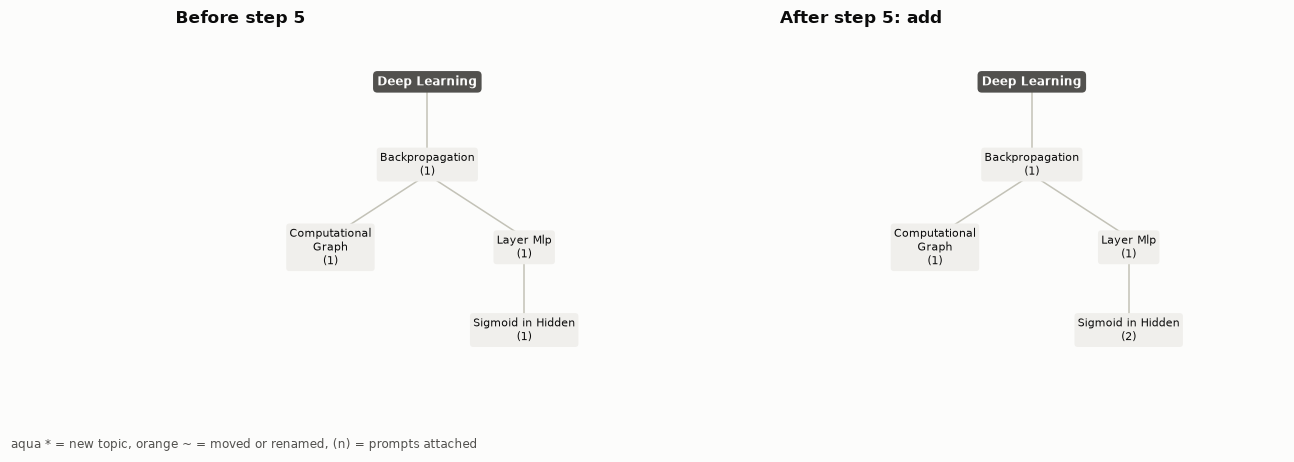

In [8]:
ch = viz.forest_change_sets(before, res.forest)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
viz.plot_forest(before, axes[0], title=f"Before step {n.step}")
viz.plot_forest(res.forest, axes[1], title=f"After step {n.step}: {ACTION_NAMES[res.action]}", **ch)
fig.text(0.01, -0.02, "aqua * = new topic, orange ~ = moved or renamed, (n) = prompts attached", fontsize=8, color=viz.TEXT_2)
viz.save(fig, FIG / "04_step_before_after.png")

## Size and solve time over whole sessions

,vars,constrs,solve_s
session,,,
s1_focused,375,534,0.008
s2_mixed,299,433,0.010
s3_drift,271,387,0.008


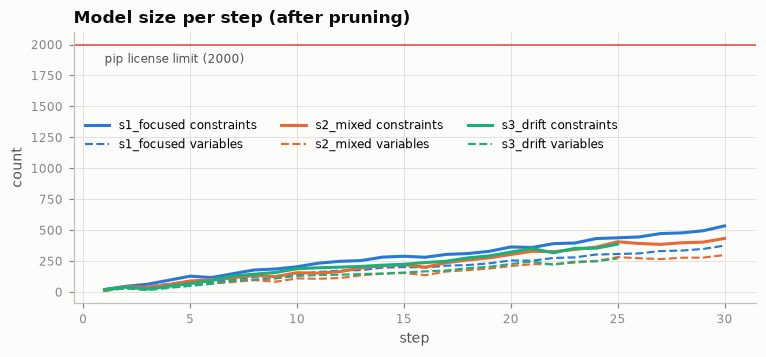

In [9]:
size_rows = []
for sid, s in sessions.items():
    for t in (trace if sid == "s1_focused" else trace_ip(s, ctx)):
        r = t["result"]
        size_rows.append({"session": sid, "step": t["prompt"].step, "vars": r.size["vars"], "constrs": r.size["constrs"],
                          "solve_s": r.solution.runtime_s, "c2_mode": r.size["c2_mode"]})
sizes = pd.DataFrame(size_rows)
fig, ax = plt.subplots(figsize=(8, 3.2))
for i, sid in enumerate(sessions):
    d = sizes[sizes["session"] == sid]
    ax.plot(d["step"], d["constrs"], color=viz.SLOTS[i], label=f"{sid} constraints")
    ax.plot(d["step"], d["vars"], color=viz.SLOTS[i], ls="--", lw=1.4, label=f"{sid} variables")
ax.axhline(2000, color=viz.SLOTS[7], lw=1)
ax.annotate("pip license limit (2000)", (1, 2000), xytext=(0, -12), textcoords="offset points", fontsize=8, color=viz.TEXT_2)
ax.set_xlabel("step")
ax.set_ylabel("count")
ax.set_title("Model size per step (after pruning)")
ax.legend(ncol=3, loc="center left", bbox_to_anchor=(0, 0.62))
viz.save(fig, FIG / "04_model_size.png")
sizes.groupby("session")[["vars", "constrs", "solve_s"]].max().round(3)

## Why `lam_G` starts at 0.5 and not at the plan's 1.0
A new group always comes with a new tree root holding one prompt. That costs
`lam_G + lam + beta * (L - 1)` (the root is below `L`). At most it gains a fit of 1 over an
existing topic with fit 0, plus `alpha_G * hg <= alpha_G`. With the start values the cost is
1.0 + 0.4 + 0.3 = 1.7 and the gain at most 1.5, so **no new group can ever be created**.
The tiny instance below shows it: a prompt that fits nothing in the old forest (fit 0) and a
proposed group that fits perfectly.

In [10]:
def tiny(lam_G):
    f = Forest(step=2)
    f.groups["g1"] = Group("g1", "Deep Learning")
    f.topics["t1"] = Topic("t1", "Backpropagation", "g1", "group")
    for i in (1, 2):
        f.prompts[f"p{i}"] = Prompt(f"p{i}", "x", i, "demo")
        f.assignment[f"p{i}"] = "t1"
    inp = IPInput(forest=f, n=Prompt("n", "SQL joins?", 3, "demo"),
                  new_topics={"N": NewTopic("N", "SQL joins")}, new_groups={"G": NewGroup("G", "Databases")},
                  s={("p1", "t1"): 1, ("p2", "t1"): 1, ("n", "t1"): 0.0, ("n", "N"): 1.0},
                  h={}, hg={("g1", "t1"): 1.0, ("G", "N"): 1.0}, w={}, v={})
    return place(inp, params.replace(lam_G=lam_G, tau=0.0)).action

bound = 1 + params.alpha_G - params.lam - params.beta * (params.L - 1)
print(f"a new group can pay off only if lam_G < 1 + alpha_G - lam - beta*(L-1) = {bound:.2f}")
pd.DataFrame([{"lam_G": v, "action": tiny(v), "meaning": ACTION_NAMES[tiny(v)]} for v in (1.0, 0.8, 0.79, 0.5)])

a new group can pay off only if lam_G < 1 + alpha_G - lam - beta*(L-1) = 0.80


,lam_G,action,meaning
0,1.00,a,add
1,0.80,a,add
2,0.79,d,new group
3,0.50,d,new group


## Unit tests
One test per outcome (a) to (e), plus rename, deletion, feasibility, depth and group limits
(`tests/test_ip.py`).

In [11]:
out = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests/test_ip.py"], cwd=ROOT, capture_output=True, text=True)
print(out.stdout.strip().splitlines()[-1])

17 passed in 0.16s


## Findings

- Every step of all three sessions solves to optimality in well under the 5-second budget, and
  stays far below the 2000 limit (maxima in the table above). Pruning (C18) keeps only a part of
  the scored pairs.
- The walkthrough step (s1, step 5) shows the IP overruling the judge. The judge's best option is
  a new topic "Bias in Layer" under Backpropagation. The IP instead adds the prompt to a topic
  with one prompt that it fits less (judge fit 3). Filling a topic below `L` removes its slack
  (`beta`), while a new topic would cost `lam` plus its own `L` slack.
- That also shows a side effect to discuss in the report: the `L` slack can pull prompts into
  small topics with a weaker fit. A smaller `beta`, or `L = 1`, weakens the pull.
- With the plan's start value `lam_G = 1.0` a new group can never be created (`1 + alpha_G` gain
  against a `lam_G + lam + beta` cost). The tiny instance flips at the bound 0.8. The config uses
  0.5, and 06 sweeps it.
- All IP unit tests pass.
- *Caveat:* every score here comes from the offline stand-in judge.